# NASA NEX-GDDP-CMIP6 annual precipitation extremes

Inspect the 2014 annual maximum daily precipitation of one ACCESS-CM2 historical model member over a small Toronto-area window. NEX uses bias adjustment and statistical downscaling to a 0.25° grid; it is a climate-model realization, not observations, a model ensemble, flood depth, or a design-rainfall product. One year does not estimate a return period. See the [NASA technical note](https://www.nccs.nasa.gov/sites/default/files/NEX-GDDP-CMIP6-Tech_Note.pdf) for method and limitations.

The [pipeline](../../pipelines/nex_gddp_cmip6_pipeline.py) reads the selected window in bounded strips and writes batches to Parquet. NEX annual files have independent revisions: this example explicitly selects version 1.0 rather than silently substituting a newer file.

NASA's [archive terms](https://registry.opendata.aws/nex-gddp-cmip6/) say the outputs are now CC0. The original CMIP6 model licence in this file says CC BY-SA; the adapter warns and retains it as historical source metadata along with the archive terms, model, member, calendar, revision and URL. Review the current archive and model terms before redistributing.

Run from a local crc-docs checkout: use `uv sync`, then launch Jupyter with
`uv run jupyter lab` and select the project kernel. The first pipeline run
requires internet access.


In [1]:
# Check the local notebook environment before running the pipeline.
import importlib.util
import subprocess
import sys
from pathlib import Path

IN_COLAB = importlib.util.find_spec("google.colab") is not None if importlib.util.find_spec("google") else False
if IN_COLAB or importlib.util.find_spec("crc_sdk") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet",
                           "--disable-pip-version-check", "plotly>=6", "crc-sdk[netcdf]>=0.11.1,<1"])
root = next((folder for folder in (Path.cwd(), *Path.cwd().parents)
             if (folder / "pipelines").is_dir()), None)
if root is None:
    raise RuntimeError("Run this notebook from a crc-docs checkout (the pipelines folder is required).")
sys.path.insert(0, str(root))

import os

import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots

STATIC_PREVIEW = os.environ.get("CRC_NOTEBOOK_STATIC_PREVIEW") == "1"
pio.renderers.default = "colab" if IN_COLAB else "plotly_mimetype+png" if STATIC_PREVIEW else "plotly_mimetype"
pio.templates.default = "plotly_white"
pio.defaults.default_width = 1000
pio.defaults.default_height = 470
from pipelines.nex_gddp_cmip6_pipeline import run
import pyarrow.parquet as pq

output = root / "pipeline_output" / "nex_gddp_cmip6"
print("Valid grid cells:", run(output))

/Users/woozyking/rtai/crc-docs/pipelines/nex_gddp_cmip6_pipeline.py:26: RestrictiveLicenceWarning: NEX original model licence metadata is 'CC-BY-SA 4.0'; NASA states the archive is now CC0. Review https://registry.opendata.aws/nex-gddp-cmip6/ and the original model terms before redistribution.
  for batch in plan.annual_extremes():


Valid grid cells: 9


In [2]:
pixels = pq.read_table(output / "annual_extremes.parquet").to_pandas()
pixels[["year", "latitude", "longitude", "value", "unit", "model", "version", "original_model_licence"]]

,year,latitude,longitude,value,unit,model,version,original_model_licence
0,2014,43.375,-79.625,28.967334,mm/day,ACCESS-CM2,1.0,CC-BY-SA 4.0
1,2014,43.375,-79.375,30.621180,mm/day,ACCESS-CM2,1.0,CC-BY-SA 4.0
2,2014,43.375,-79.125,33.989928,mm/day,ACCESS-CM2,1.0,CC-BY-SA 4.0
3,2014,43.625,-79.625,26.343161,mm/day,ACCESS-CM2,1.0,CC-BY-SA 4.0
4,2014,43.625,-79.375,27.259604,mm/day,ACCESS-CM2,1.0,CC-BY-SA 4.0
5,2014,43.625,-79.125,30.658891,mm/day,ACCESS-CM2,1.0,CC-BY-SA 4.0
6,2014,43.875,-79.625,24.648891,mm/day,ACCESS-CM2,1.0,CC-BY-SA 4.0
7,2014,43.875,-79.375,24.794728,mm/day,ACCESS-CM2,1.0,CC-BY-SA 4.0
8,2014,43.875,-79.125,27.655048,mm/day,ACCESS-CM2,1.0,CC-BY-SA 4.0


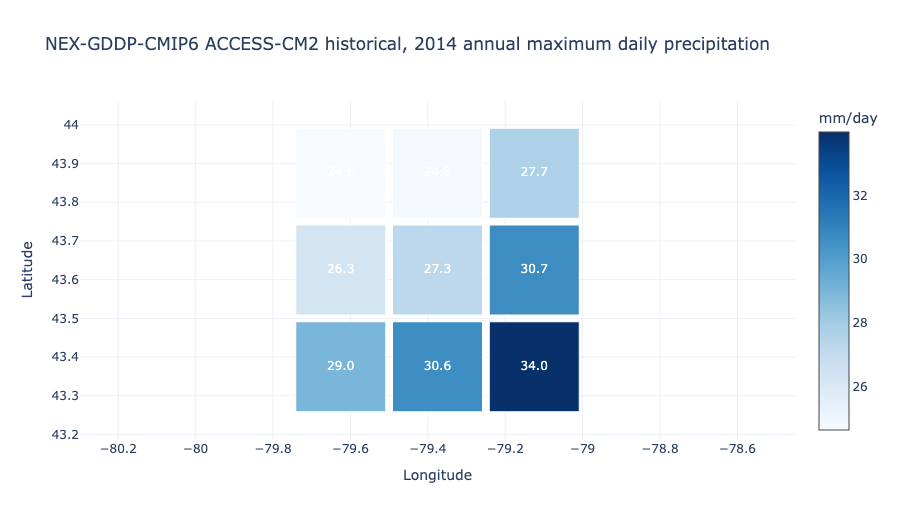

In [3]:
# One value per 0.25 degree pixel: annual maximum daily precipitation in 2014.
fig = go.Figure(go.Scatter(
    x=pixels["longitude"], y=pixels["latitude"], mode="markers+text",
    text=pixels["value"].round(1).astype(str), textfont=dict(color="white"),
    marker=dict(symbol="square", size=90, color=pixels["value"], colorscale="Blues", cmin=0,
                colorbar=dict(title="mm/day"), line=dict(width=1, color="white")),
))
fig.update_layout(title="NEX-GDDP-CMIP6 ACCESS-CM2 historical, 2014 annual maximum daily precipitation",
                  xaxis_title="Longitude", yaxis_title="Latitude", yaxis=dict(scaleanchor="x"),
                  height=520, width=900)
fig.show()


Compare multiple models and members before interpreting uncertainty, and validate the application against suitable observations. Bias adjustment and spatial downscaling do not add independent local information or eliminate model and downscaling uncertainties.